# [Lab Session 2](otsu.ipynb)

In [1]:
import numpy as np
import matplotlib.pyplot as plt

**[Task 2.1.]()** Implement Otsu thresholding as a re-usable function:

In [2]:
def otsu_thresholding(imgf):
    img8 = (imgf * 255).round().astype(np.uint8)
    
    h= np.zeros(256)

    for i in range(256):
        h[i] = np.sum(img8 == i)

    werte = np.arange(256)
    Score = np.full(256, np.inf) #np.inf damit die ersten Stellen nicht 0 bleiben. Alle die nicht 0 sind werden überschrieben.

    for i in range(256):
        n1 = h[:i].sum()
        n2 = h[i:].sum()
        if n1 == 0 or n2 == 0: # überspringt Intensitäten, die nicht vorkommen
            continue
        mu1 = np.average(werte[:i], weights=h[:i])
        mu2 = np.average(werte[i:], weights=h[i:])
        var1 = np.average((werte[:i]-mu1)**2, weights=h[:i])
        var2 = np.average((werte[i:]-mu2)**2, weights=h[i:])
        Score[i] = n1*var1 + n2*var2

    T = np.argmin(Score)

    seg = img8.copy()

    for x in range(1024):
        for y in range (1344):
            if seg[x,y] >= T:
                seg[x,y] = 1
            else :
                seg[x,y] = 0

    return seg

**[Task 2.2.]()** Implement a re-usable function to compute the Dice coefficient:

In [3]:
def compute_dice(bin1, bin2):
    assert bin1.dtype == bool
    assert bin2.dtype == bool
    
    G = bin1
    H = bin2

    dice = 2*(G*H).sum()/(G.sum() + H.sum())

    
    return dice

**[Task 2.3.]()** Test your implementations from above:

In [4]:
imgf = plt.imread('data/NIH3T3/im/dna-0.png')
imgf_seg = otsu_thresholding(imgf)

plt.figure(figsize=(15,8))
plt.imshow(imgf_seg, 'grey')
plt.colorbar ()

imgf_ref = plt.imread('data/NIH3T3/gt/0.png')

compute_dice(imgf_seg.astype(bool), imgf_ref.astype(bool))

0.8943783223933183

The result should be the same as in your [otsu.ipynb](otsu.ipynb) notebook.

**[Task 2.4.]()** Perform batch processing:

0.7528567225654604
0.647632667167185
0.42998864378556173
0.5789127665023891
0.07605520913993832
0.7965485556767932


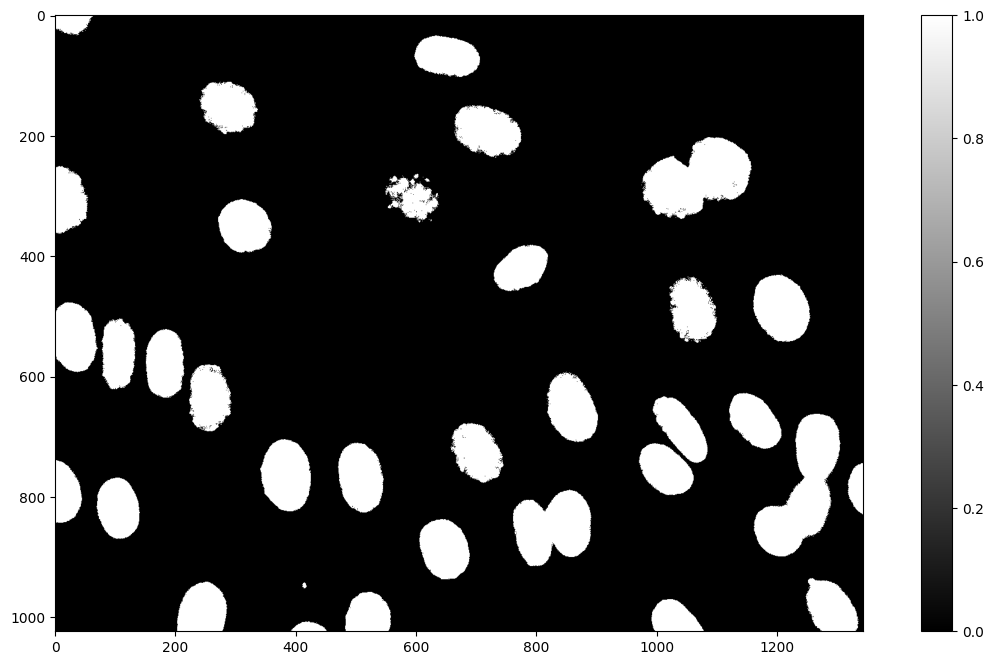

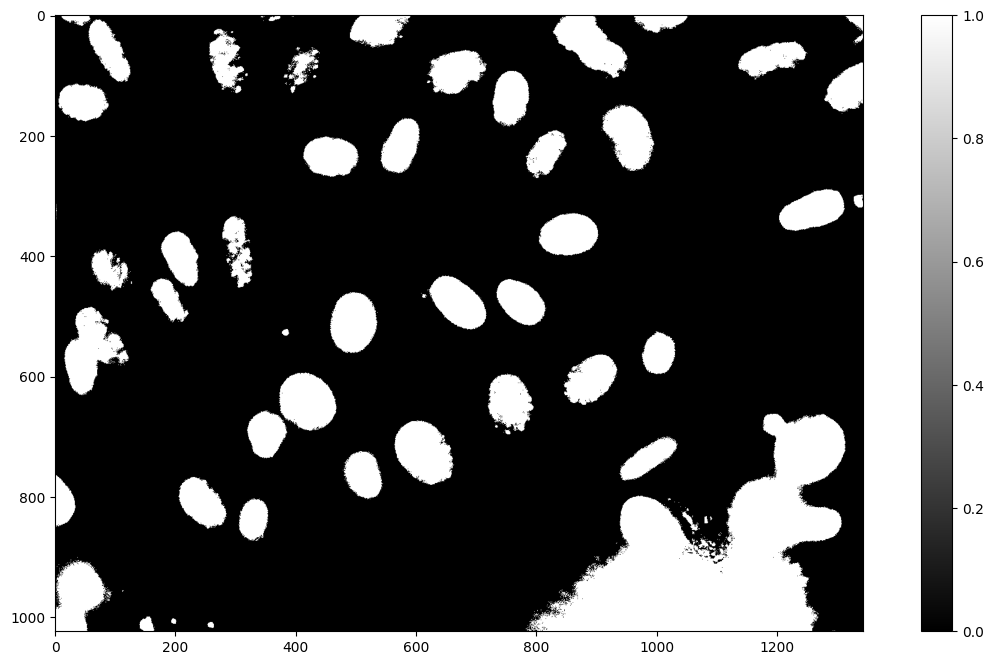

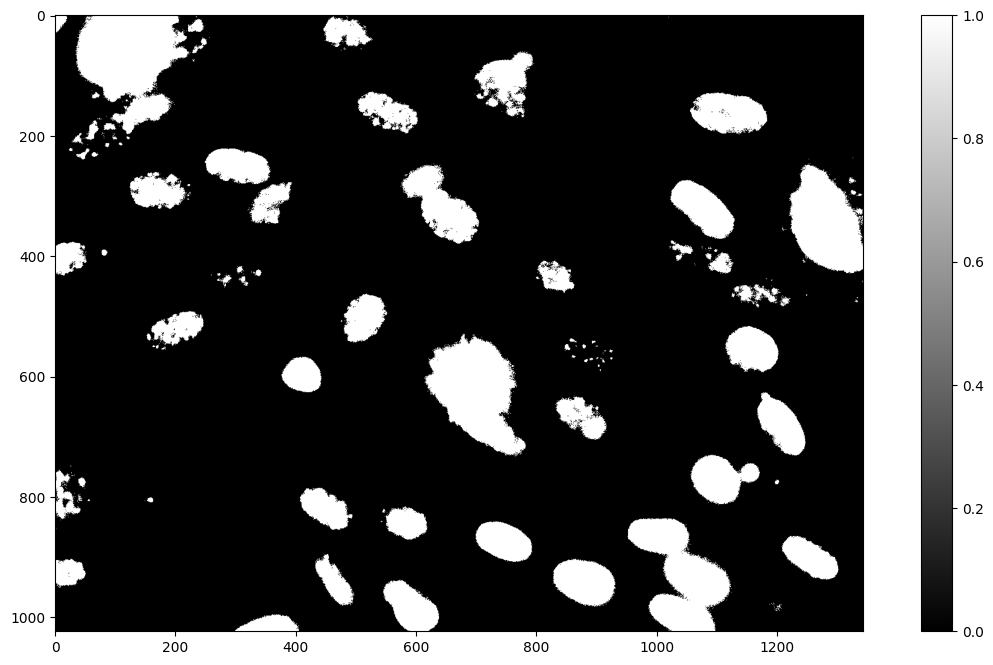

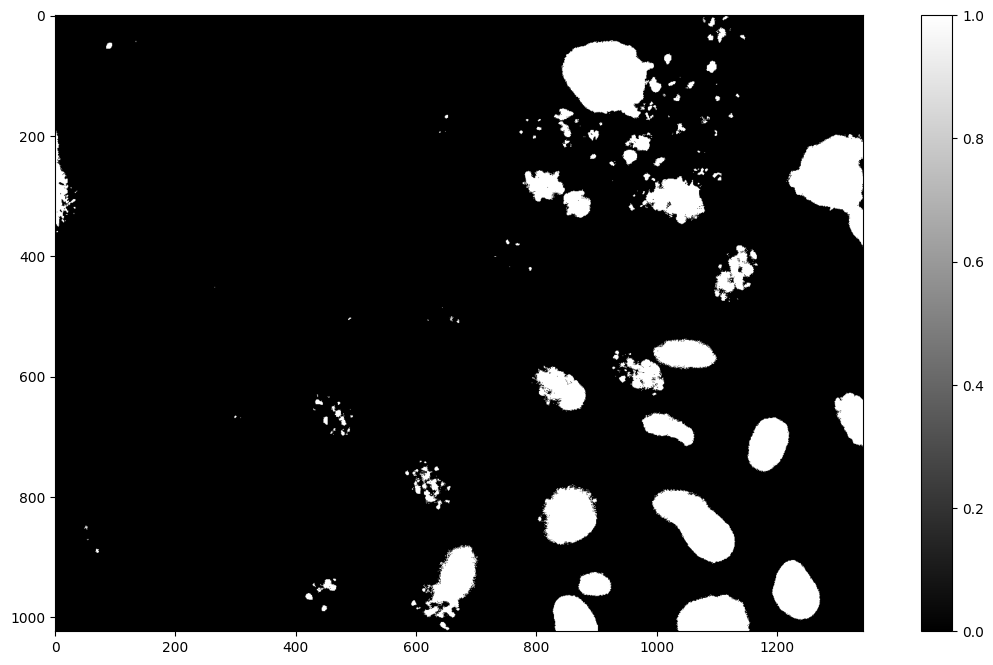

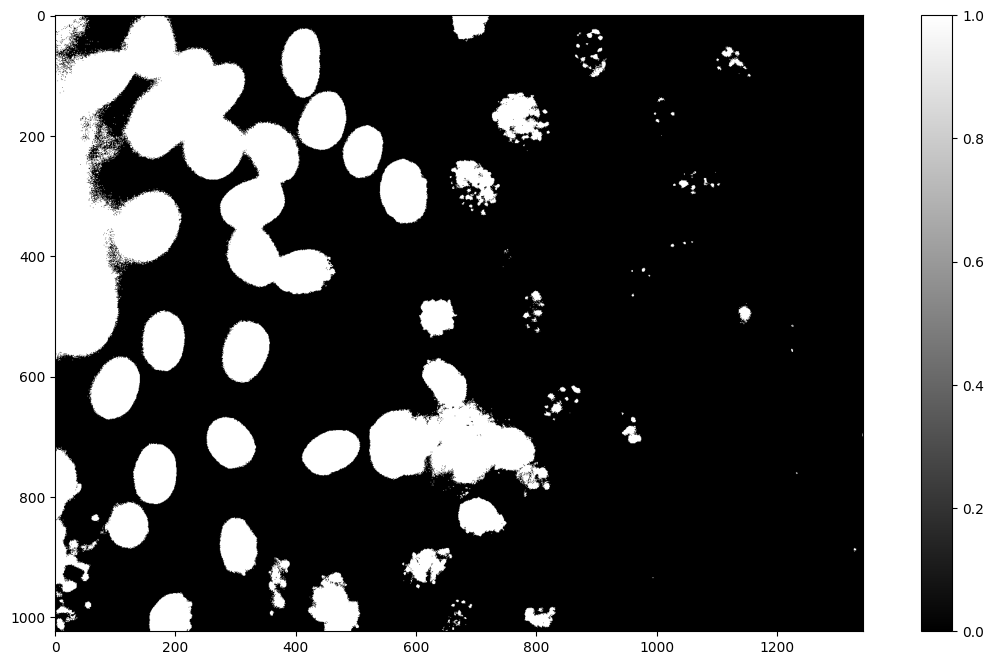

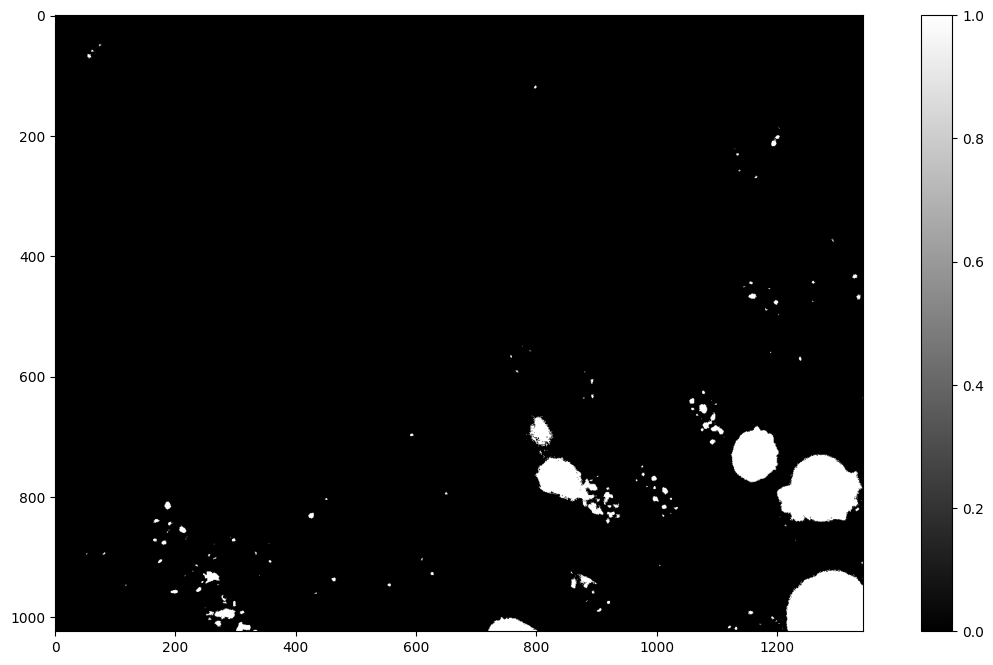

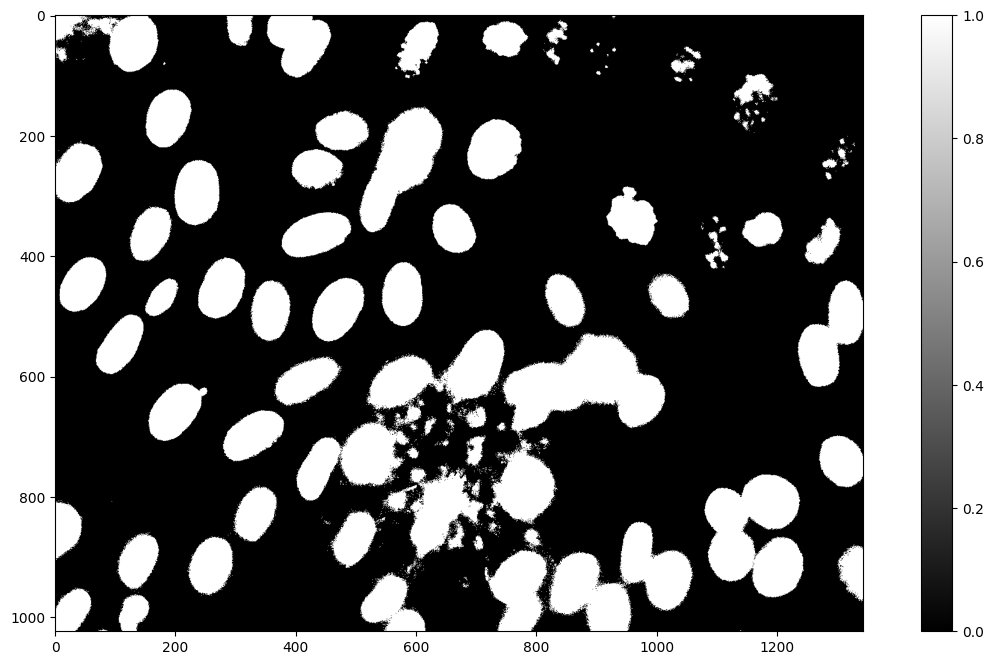

In [5]:
k = [28, 29, 33, 44, 46, 49]

for i in k:
    img_batch = plt.imread(f'data/NIH3T3/im/dna-{i}.png')
    img_batch_gt =plt.imread(f'data/NIH3T3/gt/{i}.png')

    img_batch_seg = otsu_thresholding(img_batch)
    dc = compute_dice(img_batch_seg.astype(bool), img_batch_gt.astype(bool))  # DC funktioniert nicht: str. astype fehler

    plt.figure(figsize=(15,8))
    plt.imshow(img_batch_seg, 'grey')
    plt.colorbar ()
    print(dc)
    